# 05 · Churn prediction

**Goal:** in early September, predict which customers will **not** buy during the following Christmas
season, so that marketing can target them with a pre-season campaign.

There is no subscription to cancel here, so churn has to be defined from behaviour:

> **Churn = no purchase in the 3 months after the cutoff date** (10 September – 9 December).

These are the busiest months of the year: a customer who does not buy even then has very likely gone.

The whole notebook is built around one rule: **everything the model sees must have been known at the
cutoff date.**

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src import churn, clv

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RANDOM_STATE = 42

# lifetimes (used for the BG/NBD baseline) raises pandas deprecation warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

lines = pd.read_parquet(PROCESSED_DIR / "lines_before_pairing.parquet")
transactions = pd.read_parquet(PROCESSED_DIR / "transactions.parquet")

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

def style_axis(ax):
    """Light, recessive axes so the data stands out."""
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

## Temporal split

A random train/test split would mix customers observed over the same months, so the model could learn
from the same period it is tested on. Instead, the model is trained on last year's snapshot and tested on
this year's:

| | Snapshot (cutoff) | Features from | Churn observed in |
|---|---|---|---|
| **Train** | 10 Sep 2010 | 11 Dec 2009 – 9 Sep 2010 | 10 Sep – 9 Dec 2010 |
| **Test** | 10 Sep 2011 | 11 Dec 2010 – 9 Sep 2011 | 10 Sep – 9 Dec 2011 |

- **Same season in both sets**, so the seasonality seen in phase 4 does not distort the comparison.
- **The training labels end in December 2010**, long before the test cutoff: when the model is used in
  September 2011, everything it learned from was already known.
- **Features always use the same 9-month window.** The data starts in December 2009, so the training snapshot
  has only 9 months of history; using a longer history for the test set would make features like `tenure`
  mean different things in the two sets.

The population is every customer who bought at least once in the 9 months before the cutoff.

In [2]:
TRAIN_CUTOFF = pd.Timestamp("2010-09-10")
TEST_CUTOFF = pd.Timestamp("2011-09-10")

train = churn.build_dataset(lines, transactions, TRAIN_CUTOFF)
test = churn.build_dataset(lines, transactions, TEST_CUTOFF)

# The training labels must be fully observed before the test cutoff
assert TRAIN_CUTOFF + pd.Timedelta(days=churn.HORIZON_DAYS) <= TEST_CUTOFF

for name, data in [("Train", train), ("Test", test)]:
    print(f"{name}: {len(data):,} customers, churn rate {data['churn'].mean():.1%}, "
          f"one-time buyers {data['one_time_buyer'].mean():.1%}")
print(f"Customers in both snapshots: {train.index.intersection(test.index).size:,}")

Train: 3,241 customers, churn rate 41.2%, one-time buyers 39.8%
Test: 3,234 customers, churn rate 42.3%, one-time buyers 41.3%
Customers in both snapshots: 1,863


The churn rate is almost the same in the two snapshots, which confirms that comparing the same season
works. Some customers appear in both sets, observed one year apart: this is realistic, since a business
trains on last year's behaviour of the same customer base, and their features and labels in the two sets
come from different, non-overlapping periods.

## Fixing the leakage from the cleaning phase

In phase 1, returns were paired with the purchases they cancel using the whole period. A purchase made in
August and cancelled in October would therefore be missing from the September features, although at that
date the business could still see it. `churn.lines_known_at` redoes the pairing with only the returns that
had happened before the cutoff. The difference with the phase 1 tables:

In [3]:
for cutoff in (TRAIN_CUTOFF, TEST_CUTOFF):
    start = cutoff - pd.Timedelta(days=churn.LOOKBACK_DAYS)
    known, _ = churn.lines_known_at(lines, cutoff)
    cleaned = transactions[(transactions["invoice_date"] >= start) & (transactions["invoice_date"] < cutoff)]
    print(f"{cutoff:%Y-%m-%d}: {len(known) - len(cleaned):,} purchase lines that the phase 1 tables had removed "
          f"using returns made after the cutoff (£{known['revenue'].sum() - cleaned['revenue'].sum():,.0f})")

2010-09-10: 289 purchase lines that the phase 1 tables had removed using returns made after the cutoff (£16,509)


2011-09-10: 205 purchase lines that the phase 1 tables had removed using returns made after the cutoff (£5,808)


The effect is small, but it is exactly the kind of future information that makes a model look better in
testing than it will be in production, so it is removed.

The phase 2–4 outputs (RFM segments, clusters, CLV) are **not** used as features for the same reason: they
were computed on all 24 months.

## Features

All computed from the 9 months before the cutoff (`src/churn.py`):

| Feature | Meaning |
|---|---|
| `recency`, `frequency`, `monetary` | RFM in the window (gross purchases) |
| `tenure` | Days since the first purchase in the window |
| `avg_order_value`, `distinct_products` | Size and variety of the baskets |
| `invoices_30d`, `revenue_30d`, `invoices_90d`, `revenue_90d` | Recent activity, which drops before recency grows |
| `mean_days_between` | The customer's usual gap between purchase days |
| `overdue_ratio` | Days since the last purchase ÷ usual gap: how "late" the customer is for their own rhythm |
| `return_rate` | Returned value ÷ purchased value (from the returns table) |
| `is_uk`, `one_time_buyer` | Domestic customer; only one invoice in the window |

A first look at the training set shows where the signal is:

In [4]:
train.groupby("one_time_buyer")["churn"].agg(customers="size", churn_rate="mean").round(3)

,customers,churn_rate
one_time_buyer,,
0,1951,0.293
1,1290,0.593


In [5]:
recency_band = pd.cut(train["recency"], [0, 30, 90, 180, churn.LOOKBACK_DAYS], labels=["≤ 30 days", "31–90", "91–180", "> 180"])
train.groupby(recency_band, observed=True)["churn"].agg(customers="size", churn_rate="mean").round(3)

,customers,churn_rate
recency,,
≤ 30 days,862,0.281
31–90,984,0.351
91–180,915,0.518
> 180,421,0.608


One-time buyers churn about twice as often as repeat customers, and churn grows steadily with recency, but
even among customers who bought in the last month a sizeable share does not come back. No single feature
separates the two groups cleanly.

## Baselines

A model is only worth its complexity if it beats simple rules. Each baseline produces a risk score with no
training at all:

- **Random:** AUC 0.5 by construction.
- **Recency:** customers who have not bought for longest are most at risk.
- **Frequency:** customers with fewer invoices are most at risk.
- **BG/NBD (phase 4):** fitted on the window before the test cutoff, with no labels. Two scores are tried:
  fewer expected purchases in the next 13 weeks, and 1 − P(alive).

In [6]:
X_train, y_train = train[churn.FEATURES], train["churn"]
X_test, y_test = test[churn.FEATURES], test["churn"]

# BG/NBD on the test window only: unsupervised, so it uses no churn labels
test_purchases, _ = churn.lines_known_at(lines, TEST_CUTOFF)
bg_summary = clv.customer_summary(clv.daily_purchases(test_purchases), TEST_CUTOFF - pd.Timedelta(days=1))
bgf = clv.fit_bgnbd(bg_summary["frequency"], bg_summary["recency"], bg_summary["T"])
horizon_weeks = churn.HORIZON_DAYS / clv.DAYS_PER_WEEK
expected = bgf.conditional_expected_number_of_purchases_up_to_time(
    horizon_weeks, bg_summary["frequency"], bg_summary["recency"], bg_summary["T"]).reindex(test.index)
p_alive = pd.Series(bgf.conditional_probability_alive(
    bg_summary["frequency"], bg_summary["recency"], bg_summary["T"]), index=bg_summary.index).reindex(test.index)

baseline_scores = {
    "Recency": test["recency"],
    "Frequency (fewer = riskier)": -test["frequency"],
    "BG/NBD expected purchases": -expected,
    "BG/NBD 1 − P(alive)": 1 - p_alive,
}

def evaluate(scores):
    return {"roc_auc": roc_auc_score(y_test, scores),
            "average_precision": average_precision_score(y_test, scores),
            "churn_rate_top_20pct": churn.top_share_rate(y_test, scores)}

results = {"Random": {"roc_auc": 0.5, "average_precision": y_test.mean(), "churn_rate_top_20pct": y_test.mean()}}
results.update({name: evaluate(s) for name, s in baseline_scores.items()})
pd.DataFrame(results).T.round(3)

C:\Users\maine\OneDrive\Desktop\project\customer-analytics-project\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


,roc_auc,average_precision,churn_rate_top_20pct
Random,0.500,0.423,0.423
Recency,0.684,0.592,0.655
Frequency (fewer = riskier),0.723,0.585,0.594
BG/NBD expected purchases,0.730,0.615,0.669
BG/NBD 1 − P(alive),0.351,0.401,0.362


Frequency and BG/NBD's expected purchases are already decent baselines. **1 − P(alive) is worse than
random**: it is the BG/NBD limitation found in phase 4. The model considers every one-time buyer alive with
probability 1, so they get the lowest risk score, while they are in fact the customers who churn most.

In [7]:
print(f"Median P(alive) of one-time buyers: {p_alive[test['one_time_buyer'] == 1].median():.2f}, "
      f"their churn rate: {y_test[test['one_time_buyer'] == 1].mean():.0%}")

Median P(alive) of one-time buyers: 1.00, their churn rate: 62%


## Models

Two models, each tuned with 5-fold cross-validation **on the training snapshot only**:

- **Logistic regression.** Skewed features are log-transformed and every feature is standardised. The
  transformations are inside a `Pipeline`, so in each cross-validation fold they are learned on the training
  folds only. Customers with a single purchase have no gap between purchases: the missing value is imputed
  with 0 after the log and the `one_time_buyer` flag tells the model why.
- **Gradient boosting** (`HistGradientBoostingClassifier`): handles skew and missing values natively and can
  capture interactions.

The test snapshot is used once, after the model has been chosen on cross-validation.

In [8]:
log_then_scale = make_pipeline(
    FunctionTransformer(np.log1p),
    SimpleImputer(strategy="constant", fill_value=0),
    StandardScaler(),
)
preprocess = ColumnTransformer([
    ("skewed", log_then_scale, churn.SKEWED_FEATURES),
    ("other", StandardScaler(), churn.OTHER_FEATURES),
])

candidates = {
    "Logistic regression": (
        Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=5000))]),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
    "Gradient boosting": (
        HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE),
        {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 15], "min_samples_leaf": [20, 80]},
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}
for name, (estimator, grid) in candidates.items():
    searches[name] = GridSearchCV(estimator, grid, scoring="roc_auc", cv=cv).fit(X_train, y_train)
    print(f"{name}: CV ROC-AUC {searches[name].best_score_:.3f} with {searches[name].best_params_}")

Logistic regression: CV ROC-AUC 0.722 with {'model__C': 0.01}


Gradient boosting: CV ROC-AUC 0.725 with {'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 80}


The two models are practically tied in cross-validation. The one with the higher CV AUC is chosen as the final
model, and that choice is not revisited after seeing the test results, even if the other model turns out
slightly better there: picking the winner on the test set would turn it into a second validation set and make
the reported score optimistic. Both are shown on the test set for completeness.

In [9]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
model = searches[best_name].best_estimator_
print(f"Chosen on cross-validation: {best_name}")

model_scores = {name: search.best_estimator_.predict_proba(X_test)[:, 1] for name, search in searches.items()}
results.update({name: evaluate(s) for name, s in model_scores.items()})

comparison = pd.DataFrame(results).T
comparison.style.format("{:.3f}").highlight_max(axis=0, props="font-weight: bold")

Chosen on cross-validation: Gradient boosting


,roc_auc,average_precision,churn_rate_top_20pct
Random,0.500,0.423,0.423
Recency,0.684,0.592,0.655
Frequency (fewer = riskier),0.723,0.585,0.594
BG/NBD expected purchases,0.730,0.615,0.669
BG/NBD 1 − P(alive),0.351,0.401,0.362
Logistic regression,0.747,0.638,0.678
Gradient boosting,0.745,0.630,0.675


Is the gain over the best baseline real, or could it come from the particular customers in the test set?
A bootstrap resamples the test customers 1,000 times and recomputes the difference in AUC each time:

In [10]:
best_baseline = max(baseline_scores, key=lambda n: results[n]["roc_auc"])
rng = np.random.default_rng(RANDOM_STATE)
model_score = pd.Series(model_scores[best_name], index=y_test.index)
baseline_score = baseline_scores[best_baseline]

differences = []
for _ in range(1000):
    sample = rng.integers(0, len(y_test), len(y_test))
    y_s = y_test.iloc[sample]
    differences.append(roc_auc_score(y_s, model_score.iloc[sample]) - roc_auc_score(y_s, baseline_score.iloc[sample]))
low, high = np.percentile(differences, [2.5, 97.5])
print(f"{best_name} vs {best_baseline}: AUC difference {np.mean(differences):+.3f} (95% CI {low:+.3f} to {high:+.3f})")

Gradient boosting vs BG/NBD expected purchases: AUC difference +0.016 (95% CI +0.003 to +0.027)


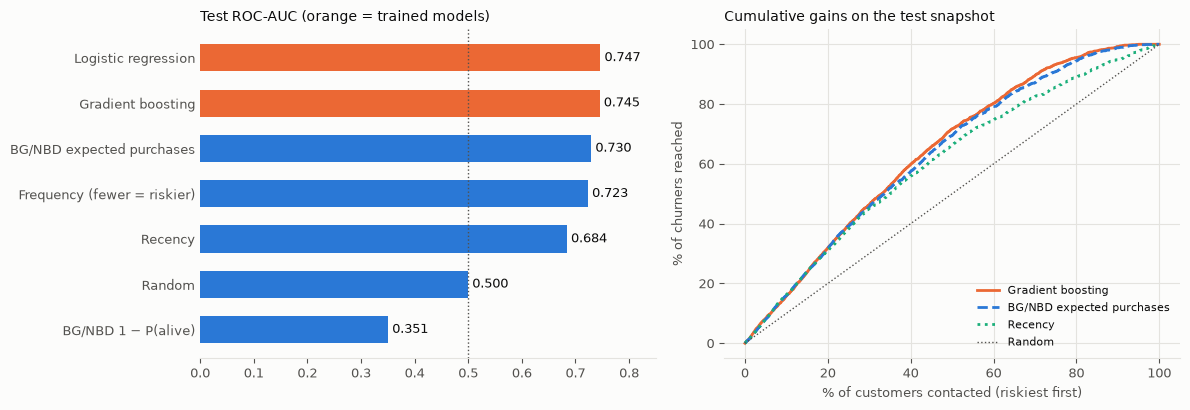

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=SURFACE)

# Left: test ROC-AUC of every approach
order = comparison["roc_auc"].sort_values().index
colors = [ORANGE if name in model_scores else BLUE for name in order]
axes[0].barh(order, comparison.loc[order, "roc_auc"], color=colors, height=0.6)
for y, value in enumerate(comparison.loc[order, "roc_auc"]):
    axes[0].text(value, y, f" {value:.3f}", va="center", color=TEXT, fontsize=9)
axes[0].axvline(0.5, color=MUTED, linewidth=1, linestyle=":")
axes[0].set_xlim(0, 0.85)
axes[0].set_title("Test ROC-AUC (orange = trained models)", loc="left", color=TEXT, fontsize=10)
axes[0].tick_params(axis="y", colors=TEXT, length=0)

# Right: cumulative gains, share of churners reached when contacting the riskiest customers first
def gains(scores):
    ordered = y_test.values[np.argsort(-np.asarray(scores))]
    return np.r_[0, np.cumsum(ordered) / ordered.sum()]

contacted = np.linspace(0, 1, len(y_test) + 1)
for label, scores, color, style in [(best_name, model_scores[best_name], ORANGE, "-"),
                                    (best_baseline, baseline_scores[best_baseline], BLUE, "--"),
                                    ("Recency", baseline_scores["Recency"], AQUA, ":")]:
    axes[1].plot(contacted * 100, gains(scores) * 100, color=color, linestyle=style, linewidth=2, label=label)
axes[1].plot([0, 100], [0, 100], color=MUTED, linewidth=1, linestyle=":", label="Random")
axes[1].set_xlabel("% of customers contacted (riskiest first)", color=MUTED, fontsize=9)
axes[1].set_ylabel("% of churners reached", color=MUTED, fontsize=9)
axes[1].set_title("Cumulative gains on the test snapshot", loc="left", color=TEXT, fontsize=10)
axes[1].legend(frameon=False, fontsize=8, labelcolor=TEXT, loc="lower right")
axes[1].grid(color=GRID, linewidth=0.8)

for ax in axes:
    style_axis(ax)
axes[0].spines["left"].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_churn_results.png", dpi=150, facecolor=SURFACE)
plt.show()

## What drives the prediction

Permutation importance measures how much the test AUC drops when one feature is shuffled, breaking its link
with churn. It works for any model and needs no refitting, so it uses the test set without leaking anything.
Correlated features share their importance (frequency, monetary and distinct products move together), so a
feature with low importance is not necessarily useless: its information may already be carried by another one.

In [12]:
importance = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10,
                                    random_state=RANDOM_STATE)
pd.Series(importance.importances_mean, index=churn.FEATURES).sort_values(ascending=False).round(4)

distinct_products    0.0222
overdue_ratio        0.0165
recency              0.0115
mean_days_between    0.0081
revenue_90d          0.0078
avg_order_value      0.0036
frequency            0.0033
tenure               0.0031
monetary             0.0025
return_rate          0.0023
revenue_30d          0.0019
invoices_90d         0.0002
invoices_30d         0.0001
is_uk                0.0000
one_time_buyer       0.0000
dtype: float64

The most useful signals are how varied a customer's purchases are, how **late** they are compared with their own
buying rhythm (`overdue_ratio`) and plain recency. The overdue ratio is the same idea that BG/NBD is built on:
silence only means something relative to how often a customer usually buys.

## Using the scores: risk or revenue at risk?

Suppose marketing can contact 500 customers before Christmas. Ranking them by churn risk alone finds the most
churners, but many of them are small accounts. Multiplying the risk by what each customer spent in the last
9 months (known at the cutoff) gives the **revenue at risk**, which targets fewer churners but much more value:

In [13]:
scored = test.assign(churn_risk=model_score)
scored["revenue_at_risk"] = scored["churn_risk"] * scored["monetary"]

CAMPAIGN_SIZE = 500
targeting = pd.DataFrame({
    rule: {
        "actual_churn_rate": top["churn"].mean(),
        "churners_reached": top["churn"].sum(),
        "past_revenue_of_churners_reached": top.loc[top["churn"] == 1, "monetary"].sum(),
    }
    for rule, top in [("Highest churn risk", scored.nlargest(CAMPAIGN_SIZE, "churn_risk")),
                      ("Highest revenue at risk", scored.nlargest(CAMPAIGN_SIZE, "revenue_at_risk"))]
}).T
targeting.style.format({"actual_churn_rate": "{:.0%}", "churners_reached": "{:,.0f}",
                        "past_revenue_of_churners_reached": "£{:,.0f}"})

,actual_churn_rate,churners_reached,past_revenue_of_churners_reached
Highest churn risk,67%,337,"£119,131"
Highest revenue at risk,35%,173,"£374,527"


The two rankings answer different questions. Ranking by risk is right for a cheap, automated campaign, where
every churner reached counts the same. Ranking by revenue at risk is right for expensive actions such as a call
from an account manager: it reaches fewer churners, but customers worth about three times as much in past
revenue. In both cases the churn score is what makes the list better than targeting by spend alone.

## Save the scores

In [14]:
scored.to_parquet(PROCESSED_DIR / "churn_scores.parquet")
print(f"Saved churn risk for {len(scored):,} customers at {TEST_CUTOFF:%Y-%m-%d}")

Saved churn risk for 3,234 customers at 2011-09-10


## Summary

| Choice | Decision | Reason |
|---|---|---|
| Churn definition | No purchase in the 3 months after 10 September | Non-contractual setting; the Christmas season is when active customers buy |
| Split | Train on the 2010 snapshot, test on the 2011 snapshot | Temporal, same season, training labels known before the test cutoff |
| Feature window | Same 9 months before each cutoff | Comparable features in train and test |
| Leakage | Returns re-paired with only returns before the cutoff; phase 2–4 outputs not used | They contain information from after the cutoff |
| Baselines | Random, recency, frequency, BG/NBD | A model must beat simple rules to be worth it |
| Models | Logistic regression vs gradient boosting, tuned with CV on train only | Test set used once, after choosing on CV |
| Metrics | ROC-AUC, average precision, churn rate in the riskiest 20% | Ranking quality and the business view of a campaign |

**Conclusion:** there is real signal, and the model beats every baseline on the test season, but the gain over
the best simple rule is modest. Churn without a contract is hard to predict from purchase history alone; data
such as website visits, email engagement or customer service contacts would be the natural next step.